# Graph ML — GCN Edge Classification & Label Propagation (cyber-attacks-dataset)

**Goal:** Model the network as a graph and classify each traffic flow (edge) as BENIGN or ATTACK using:
1. **GCN Edge Classifier** — 2-layer GCN for node embeddings + MLP edge classifier
2. **Label Propagation** — parameter-free edge classification via IP reputation propagation
3. **Ensemble** — majority vote across XGBoost, GCN, and LP

**Input:** Prepared data from `01_data_preparation.ipynb` (saved in `prepared_data/`).
**Dataset:** Always uses the **TL** table since graph construction requires `src_ip`, `dst_ip` and `bidirectional_first_seen_ms`.
**Split:** Per-label chronological 70/15/15 — the same rows as the Per-Label Stratified Chronological Split in `02_standard_ml.ipynb`, so the XGBoost test predictions saved there line up flow by flow with the GCN and LP predictions.
**XGBoost baseline:** Loaded from saved results in `02_standard_ml.ipynb` (not retrained here).
**Small GPUs:** when the per-flow edge features do not fit in GPU memory (e.g. a 2 GB MX450), they stay in RAM and each mini-batch is copied to the GPU.

## Configuration

In [1]:
from pydantic import BaseModel, Field
from typing import Optional


class GraphDataConfig(BaseModel):
    """Data loading and split settings."""
    prepared_data_dir: str = Field(default="prepared_data", description="Directory with prepared data")
    use_correlation_features: bool = Field(default=False, description="Use correlation-selected feature subset")
    random_state: int = Field(default=42, description="Random seed")


class GCNConfig(BaseModel):
    """GCN Edge Classifier training settings."""
    hidden_dim: int = Field(default=128, description="GCN hidden dimension")
    dropout: float = Field(default=0.3)
    learning_rate: float = Field(default=1e-3)
    weight_decay: float = Field(default=1e-4)
    num_epochs: int = Field(default=100)
    edge_batch_size: int = Field(default=65536, description="Mini-batch size for edge classification")
    patience: int = Field(default=15, description="Early stopping patience")
    scheduler_factor: float = Field(default=0.5)
    scheduler_patience: int = Field(default=5)
    edge_features_on_gpu: Optional[bool] = Field(default=None, description="Keep all edge tensors in GPU memory; None = only if they fit")


class LPConfig(BaseModel):
    """Label Propagation settings."""
    max_iterations: int = Field(default=100)
    convergence_tol: float = Field(default=1e-8)
    threshold_search_step: float = Field(default=0.01, description="Step for threshold sweep")


class EnsembleConfig(BaseModel):
    """Ensemble settings."""
    run_ensemble: bool = Field(default=True)


data_cfg = GraphDataConfig()
gcn_cfg = GCNConfig()
lp_cfg = LPConfig()
ens_cfg = EnsembleConfig()

print("Configuration loaded:")
print(f"  Data: dir={data_cfg.prepared_data_dir}, corr_features={data_cfg.use_correlation_features}")
print(f"  GCN: hidden={gcn_cfg.hidden_dim}, epochs={gcn_cfg.num_epochs}, batch={gcn_cfg.edge_batch_size}, patience={gcn_cfg.patience}")
print(f"  LP: max_iter={lp_cfg.max_iterations}, tol={lp_cfg.convergence_tol}")

Configuration loaded:
  Data: dir=prepared_data, corr_features=False
  GCN: hidden=128, epochs=100, batch=65536, patience=15
  LP: max_iter=100, tol=1e-08


## Imports & Data Loading

In [2]:
import os
import gc
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', '{:.4f}'.format)

%matplotlib inline
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100

NOTEBOOK_T0 = time.time()
print("Base imports loaded.")

Base imports loaded.


In [3]:
import subprocess, sys

try:
    import torch
    print(f"PyTorch already installed: {torch.__version__}, CUDA: {torch.cuda.is_available()}")
except ImportError:
    print("Installing PyTorch (CUDA 12.1)...")
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'torch', '--index-url', 'https://download.pytorch.org/whl/cu121'])
    import torch
    print(f"PyTorch installed: {torch.__version__}, CUDA: {torch.cuda.is_available()}")

try:
    import torch_geometric
    print(f"PyG already installed: {torch_geometric.__version__}")
except ImportError:
    print("Installing PyG...")
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'torch-geometric'])
    import torch_geometric
    print(f"PyG installed: {torch_geometric.__version__}")

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch_geometric.data import Data
from torch_geometric.utils import to_undirected

gcn_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\nUsing device: {gcn_device}")
if gcn_device.type == 'cuda':
    props = torch.cuda.get_device_properties(0)
    print(f"  GPU: {props.name} ({props.total_memory / 1e9:.1f} GB)")
else:
    print(f"  CPU threads: {torch.get_num_threads()}")

# CUDA nvrtc fix (if needed)
try:
    import ctypes
    nvrtc_dir = "/usr/local/lib/python3.11/dist-packages/nvidia/cuda_nvrtc/lib"
    if os.path.exists(nvrtc_dir):
        os.environ["LD_LIBRARY_PATH"] = nvrtc_dir + ":" + os.environ.get("LD_LIBRARY_PATH", "")
        ctypes.cdll.LoadLibrary(os.path.join(nvrtc_dir, "libnvrtc.so.12"))
        print("libnvrtc.so.12 loaded successfully.")
except Exception:
    pass

PyTorch already installed: 2.14.1+cpu, CUDA: False


PyG already installed: 2.8.1

Using device: cpu
  CPU threads: 4


In [4]:
from pathlib import Path


def resolve_existing_path(path_str: str) -> Path:
    p = Path(path_str)
    if p.exists():
        return p

    cwd = Path.cwd()
    for base in [cwd, cwd.parent, cwd.parent.parent]:
        candidate = base / path_str
        if candidate.exists():
            return candidate

    raise FileNotFoundError(f"Path not found: {path_str}")


prepared_data_dir = resolve_existing_path(data_cfg.prepared_data_dir)
print(f"Using prepared_data_dir: {prepared_data_dir}")

meta_path = prepared_data_dir / 'metadata.json'
with open(meta_path, 'r', encoding='utf-8') as f:
    metadata = json.load(f)

feature_cols = metadata['feature_cols']
label_mapping = metadata['label_mapping']
ip_src_col, ip_dst_col = metadata['ip_cols']
time_col = metadata['time_col']

if data_cfg.use_correlation_features and 'selected_feature_cols' in metadata:
    active_feature_cols = metadata['selected_feature_cols']
    print(f"Using correlation-selected features: {len(active_feature_cols)}")
else:
    active_feature_cols = feature_cols
    if data_cfg.use_correlation_features:
        print("WARNING: use_correlation_features=True but no selected features in metadata. Using all features.")
    print(f"Using all features: {len(active_feature_cols)}")

tl_df = pd.read_parquet(prepared_data_dir / 'tl_prepared.parquet')
print(f"TL dataset loaded: {tl_df.shape[0]:,} rows x {tl_df.shape[1]} cols")
print(f"Endpoint columns: {ip_src_col}, {ip_dst_col}")

le = LabelEncoder()
le.classes_ = np.array(sorted(label_mapping.keys(), key=lambda x: label_mapping[x]))
class_names = le.classes_

Using prepared_data_dir: prepared_data
Using all features: 132


TL dataset loaded: 2,263,421 rows x 140 cols
Endpoint columns: src_ip, dst_ip


## Per-Label Chronological Split

Reconstruct the same Per-Label Chronological Split used in standard ML for fair comparison.

In [5]:
# Deduplicate on all feature columns + Label (as 02_standard_ml.ipynb does) and parse timestamps
ts_dedup_cols = feature_cols + ['Label']
ts_before = len(tl_df)
tl_df_dedup = tl_df.drop_duplicates(subset=ts_dedup_cols, keep='first').copy()
print(f"Deduplication: {ts_before:,} -> {len(tl_df_dedup):,}")
del tl_df
gc.collect()

tl_df_dedup['Timestamp_parsed'] = pd.to_datetime(tl_df_dedup[time_col], unit='ms', utc=True)
tl_df_dedup['binary_label'] = (tl_df_dedup['Label'] != 'BENIGN').astype(int)

# Per-label chronological 70/15/15 split
ls_train_parts, ls_val_parts, ls_test_parts = [], [], []

for label in sorted(tl_df_dedup['Label'].unique()):
    label_df = tl_df_dedup[tl_df_dedup['Label'] == label]
    label_sorted = label_df.sort_values('Timestamp_parsed', kind='stable').reset_index(drop=True)
    n = len(label_sorted)

    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    ls_train_parts.append(label_sorted.iloc[:train_end])
    ls_val_parts.append(label_sorted.iloc[train_end:val_end])
    ls_test_parts.append(label_sorted.iloc[val_end:])

ls_train_full = pd.concat(ls_train_parts, ignore_index=True)
ls_val_full = pd.concat(ls_val_parts, ignore_index=True)
ls_test_full = pd.concat(ls_test_parts, ignore_index=True)
del ls_train_parts, ls_val_parts, ls_test_parts

print(f"\nTrain: {len(ls_train_full):,}, Val: {len(ls_val_full):,}, Test: {len(ls_test_full):,}")

# Verify all attack types present
for name, part in [('Train', ls_train_full), ('Val', ls_val_full), ('Test', ls_test_full)]:
    n_types = part[part['binary_label'] == 1]['Label'].nunique()
    print(f"  {name} attack types: {n_types}")

Deduplication: 2,263,421 -> 629,540



Train: 440,652, Val: 94,428, Test: 94,460
  Train attack types: 49
  Val attack types: 43
  Test attack types: 53


---
## GCN Edge Classification

### Architecture
```
Network Topology Graph (nodes = IPs, topology edges = unique IP pairs)
  → 2-layer GCN → Node Embeddings
  → Edge Classifier MLP: concat(h_src, h_dst, flow_features) → BENIGN/ATTACK
```

### Key Design Decisions
- **Transductive**: one graph, train/val/test edge masks from per-label chronological split
- **No leakage**: node features = mean of training edge features only; scaler fit on training edges only
- **Mini-batch training**: 64K edges per batch
- **Class-weighted BCE**: handles imbalance in unbalanced training set
- **Memory placement**: node tensors live on the training device; per-edge tensors move to the GPU only if they fit

In [6]:
# --- Graph construction from per-label chronological split ---

# Reconstruct full dataset in split order: train -> val -> test
gcn_df = pd.concat([ls_train_full, ls_val_full, ls_test_full], ignore_index=True)
n_train_g = len(ls_train_full)
n_val_g = len(ls_val_full)
n_test_g = len(ls_test_full)
print(f"Full dataset: {len(gcn_df):,} flows (train={n_train_g:,}, val={n_val_g:,}, test={n_test_g:,})")

# --- Map unique IPs to node indices ---
all_ips = pd.unique(gcn_df[[ip_src_col, ip_dst_col]].values.ravel())
ip_to_idx = {ip: i for i, ip in enumerate(all_ips)}
num_nodes = len(all_ips)
print(f"Unique IPs (nodes): {num_nodes}")

# --- Build full edge index (all flows) ---
src_idx = gcn_df[ip_src_col].map(ip_to_idx).values.astype(np.int64)
dst_idx = gcn_df[ip_dst_col].map(ip_to_idx).values.astype(np.int64)
full_edge_index = torch.tensor(np.stack([src_idx, dst_idx]), dtype=torch.long)

# --- Build topology edge index (unique IP pairs, undirected, for GCN message passing) ---
topo_pairs = np.unique(np.stack([src_idx, dst_idx], axis=1), axis=0)
topo_edge_index = torch.tensor(topo_pairs.T, dtype=torch.long)
topo_edge_index = to_undirected(topo_edge_index)
print(f"Topology edges (unique, undirected): {topo_edge_index.shape[1]}")

# --- Edge features: scale using training edges only ---
scaler_gcn = RobustScaler()
edge_feats_raw = gcn_df[active_feature_cols].to_numpy(dtype=np.float32)
scaler_gcn.fit(edge_feats_raw[:n_train_g])
edge_feats_scaled = scaler_gcn.transform(edge_feats_raw).astype(np.float32)
del edge_feats_raw
edge_attr = torch.from_numpy(edge_feats_scaled)

# --- Edge labels (binary) ---
edge_labels = torch.tensor(gcn_df['binary_label'].values.astype(np.float32), dtype=torch.float)

# --- Split masks ---
train_mask = torch.zeros(len(gcn_df), dtype=torch.bool)
train_mask[:n_train_g] = True
val_mask = torch.zeros(len(gcn_df), dtype=torch.bool)
val_mask[n_train_g:n_train_g + n_val_g] = True
test_mask = torch.zeros(len(gcn_df), dtype=torch.bool)
test_mask[n_train_g + n_val_g:] = True

# --- Node features: mean of incident training-edge features (no leakage) ---
node_feat_dim = len(active_feature_cols)
node_feat_accum = np.zeros((num_nodes, node_feat_dim), dtype=np.float64)
node_feat_count = np.zeros(num_nodes, dtype=np.float64)

train_edge_feats = edge_feats_scaled[:n_train_g]
train_src = src_idx[:n_train_g]
train_dst = dst_idx[:n_train_g]

np.add.at(node_feat_accum, train_src, train_edge_feats)
np.add.at(node_feat_count, train_src, 1)
np.add.at(node_feat_accum, train_dst, train_edge_feats)
np.add.at(node_feat_count, train_dst, 1)

has_train = node_feat_count > 0
node_feat_accum[has_train] /= node_feat_count[has_train, None]
x = torch.tensor(node_feat_accum.astype(np.float32), dtype=torch.float)

n_no_train = int((~has_train).sum())
print(f"Nodes with training edges: {int(has_train.sum())} / {num_nodes}")
if n_no_train > 0:
    print(f"  Nodes without training edges (zero features): {n_no_train}")

# --- Build PyG Data object ---
data = Data(x=x, edge_index=full_edge_index, edge_attr=edge_attr)
data.topo_edge_index = topo_edge_index
data.edge_labels = edge_labels
data.train_mask = train_mask
data.val_mask = val_mask
data.test_mask = test_mask

print(f"\nGraph summary:")
print(f"  Nodes:              {data.num_nodes:,}")
print(f"  Flow-edges (total): {data.num_edges:,}")
print(f"  Topology edges:     {topo_edge_index.shape[1]:,}")
print(f"  Node feature dim:   {data.x.shape[1]}")
print(f"  Edge feature dim:   {data.edge_attr.shape[1]}")
print(f"  Train edges: {train_mask.sum().item():,}  (ATTACK: {int((edge_labels[train_mask] == 1).sum()):,})")
print(f"  Val edges:   {val_mask.sum().item():,}  (ATTACK: {int((edge_labels[val_mask] == 1).sum()):,})")
print(f"  Test edges:  {test_mask.sum().item():,}  (ATTACK: {int((edge_labels[test_mask] == 1).sum()):,})")

# --- Move to device: node tensors always; per-edge tensors only if they fit in GPU memory ---
edge_bytes = sum(t.element_size() * t.nelement() for t in (data.edge_attr, data.edge_index, data.edge_labels))
if gcn_device.type == 'cuda':
    free_bytes, _ = torch.cuda.mem_get_info()
    edges_on_gpu = gcn_cfg.edge_features_on_gpu if gcn_cfg.edge_features_on_gpu is not None else edge_bytes < 0.4 * free_bytes
else:
    edges_on_gpu = True  # CPU training: everything already lives in RAM
edge_device = gcn_device if edges_on_gpu else torch.device('cpu')

data.x = data.x.to(gcn_device)
data.topo_edge_index = data.topo_edge_index.to(gcn_device)
for attr in ('edge_index', 'edge_attr', 'edge_labels', 'train_mask', 'val_mask', 'test_mask'):
    setattr(data, attr, getattr(data, attr).to(edge_device))
print(f"\nNode tensors on {gcn_device}; edge tensors ({edge_bytes / 1e9:.2f} GB) on {edge_device}")

Full dataset: 629,540 flows (train=440,652, val=94,428, test=94,460)


Unique IPs (nodes): 134


Topology edges (unique, undirected): 1342


Nodes with training edges: 110 / 134
  Nodes without training edges (zero features): 24

Graph summary:
  Nodes:              134
  Flow-edges (total): 629,540
  Topology edges:     1,342
  Node feature dim:   132
  Edge feature dim:   132
  Train edges: 440,652  (ATTACK: 392,196)
  Val edges:   94,428  (ATTACK: 84,045)
  Test edges:  94,460  (ATTACK: 84,076)

Node tensors on cpu; edge tensors (0.34 GB) on cpu


In [7]:
# --- GCN Edge Classifier Model ---

class GCNEdgeClassifier(nn.Module):
    """
    2-layer GCN for node embeddings (on topology graph) +
    MLP edge classifier (on flow features + node embeddings).
    """
    def __init__(self, node_feat_dim, edge_feat_dim, hidden_dim=128, dropout=0.3):
        super().__init__()
        # GCN layers operate on the deduplicated topology graph
        self.conv1 = GCNConv(node_feat_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.dropout_rate = dropout

        # Edge classifier MLP: concat(h_src, h_dst, edge_features) -> output
        mlp_input_dim = hidden_dim * 2 + edge_feat_dim
        self.edge_mlp = nn.Sequential(
            nn.Linear(mlp_input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def get_node_embeddings(self, x, topo_edge_index):
        """GCN message passing on the topology graph -> node embeddings."""
        h = F.relu(self.conv1(x, topo_edge_index))
        h = F.dropout(h, p=self.dropout_rate, training=self.training)
        h = self.conv2(h, topo_edge_index)
        return h

    def classify_edges_batch(self, h, edge_index, edge_attr, indices):
        """Classify a batch of edges given precomputed node embeddings (edge tensors may live in RAM)."""
        src = edge_index[0, indices].to(h.device, non_blocking=True)
        dst = edge_index[1, indices].to(h.device, non_blocking=True)
        batch_attr = edge_attr[indices].to(h.device, non_blocking=True)
        edge_repr = torch.cat([h[src], h[dst], batch_attr], dim=1)
        return self.edge_mlp(edge_repr).squeeze(-1)


gcn_model = GCNEdgeClassifier(
    node_feat_dim=data.x.shape[1],
    edge_feat_dim=data.edge_attr.shape[1],
    hidden_dim=gcn_cfg.hidden_dim,
    dropout=gcn_cfg.dropout,
).to(gcn_device)

total_params = sum(p.numel() for p in gcn_model.parameters())
print(f"Model: GCNEdgeClassifier")
print(f"  Total parameters: {total_params:,}")
print(f"\n{gcn_model}")


# --- Helper: evaluate edges in memory-safe chunks ---
@torch.no_grad()
def evaluate_edges(model, data, indices, chunk_size=65536):
    """Forward pass on edges in chunks -> concatenated logits."""
    model.eval()
    h = model.get_node_embeddings(data.x, data.topo_edge_index)
    all_logits = []
    for i in range(0, len(indices), chunk_size):
        chunk = indices[i:i + chunk_size]
        logits = model.classify_edges_batch(h, data.edge_index, data.edge_attr, chunk)
        all_logits.append(logits)
    return torch.cat(all_logits)

Model: GCNEdgeClassifier
  Total parameters: 91,649

GCNEdgeClassifier(
  (conv1): GCNConv(132, 128)
  (conv2): GCNConv(128, 128)
  (edge_mlp): Sequential(
    (0): Linear(in_features=388, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


Class balance — BENIGN: 48,456, ATTACK: 392,196, pos_weight: 0.12
Training for up to 100 epochs (batch_size=65,536, patience=15)...



Epoch   1 | Train Loss: 16.9195 | Val Loss: 1.1077 | Val Acc: 0.9888 | Val F1: 0.9710 | LR: 1.00e-03 | 5s


Epoch   5 | Train Loss: 0.3347 | Val Loss: 0.2287 | Val Acc: 0.9986 | Val F1: 0.9963 | LR: 1.00e-03 | 21s


Epoch  10 | Train Loss: 0.0843 | Val Loss: 0.0757 | Val Acc: 0.9997 | Val F1: 0.9992 | LR: 1.00e-03 | 42s


Epoch  15 | Train Loss: 0.0495 | Val Loss: 0.0600 | Val Acc: 0.9998 | Val F1: 0.9994 | LR: 1.00e-03 | 61s


Epoch  20 | Train Loss: 0.0285 | Val Loss: 0.0520 | Val Acc: 0.9998 | Val F1: 0.9995 | LR: 1.00e-03 | 80s


Epoch  25 | Train Loss: 0.0264 | Val Loss: 0.0443 | Val Acc: 0.9998 | Val F1: 0.9995 | LR: 1.00e-03 | 99s


Epoch  30 | Train Loss: 0.0267 | Val Loss: 0.0387 | Val Acc: 0.9998 | Val F1: 0.9995 | LR: 5.00e-04 | 117s


Epoch  35 | Train Loss: 0.0294 | Val Loss: 0.0362 | Val Acc: 0.9998 | Val F1: 0.9996 | LR: 2.50e-04 | 136s



Early stopping at epoch 39. Best epoch: 24 (Val F1: 0.9996)

Training complete in 150.0s
Restored best model from epoch 24


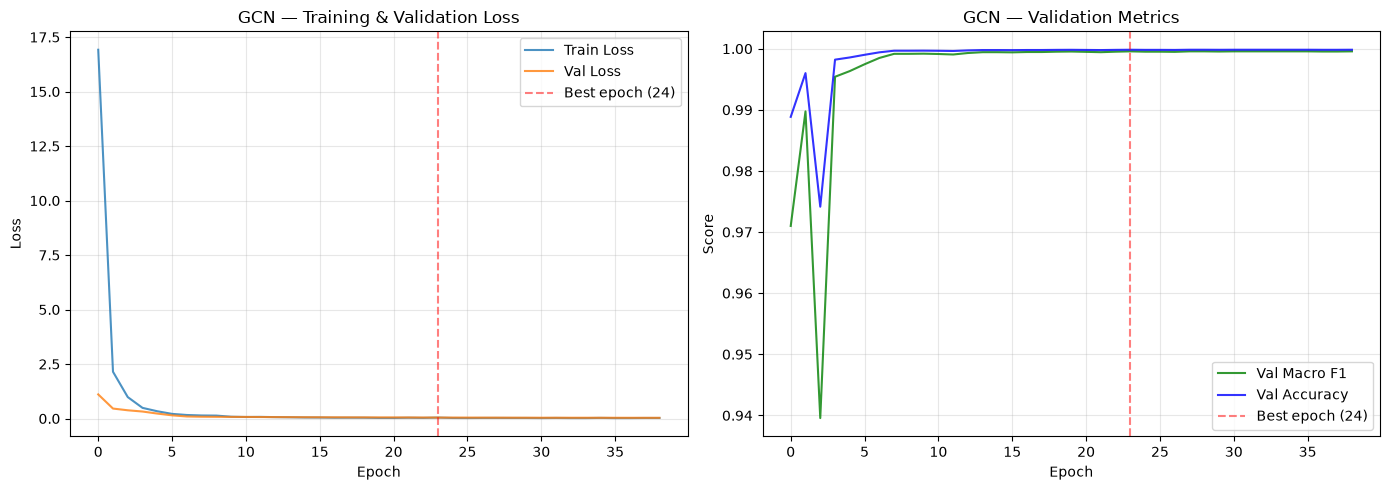

In [8]:
# --- Training loop: mini-batch edges with early stopping ---

# Precompute index tensors (on the device holding the edge tensors)
train_idx = data.train_mask.nonzero(as_tuple=False).squeeze(1)
val_idx = data.val_mask.nonzero(as_tuple=False).squeeze(1)
val_labels = data.edge_labels[val_idx].to(gcn_device)
val_true = val_labels.cpu().numpy().astype(int)

# Class weight for imbalanced training set
n_pos_train = int((data.edge_labels[data.train_mask] == 1).sum())
n_neg_train = int((data.edge_labels[data.train_mask] == 0).sum())
pos_weight = torch.tensor([n_neg_train / n_pos_train], device=gcn_device)
print(f"Class balance — BENIGN: {n_neg_train:,}, ATTACK: {n_pos_train:,}, pos_weight: {pos_weight.item():.2f}")

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(gcn_model.parameters(), lr=gcn_cfg.learning_rate, weight_decay=gcn_cfg.weight_decay)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=gcn_cfg.scheduler_factor, patience=gcn_cfg.scheduler_patience
)

# Early stopping
best_val_f1 = 0.0
best_epoch = 0
patience_counter = 0
best_state = None

history = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'val_acc': []}

print(f"Training for up to {gcn_cfg.num_epochs} epochs "
      f"(batch_size={gcn_cfg.edge_batch_size:,}, patience={gcn_cfg.patience})...\n")
t0_total = time.time()

for epoch in range(1, gcn_cfg.num_epochs + 1):
    # --- Train (mini-batch over edges) ---
    gcn_model.train()
    perm = torch.randperm(len(train_idx), device=train_idx.device)
    epoch_loss = 0.0
    n_batches = 0

    for i in range(0, len(perm), gcn_cfg.edge_batch_size):
        batch_perm = perm[i:i + gcn_cfg.edge_batch_size]
        batch_idx = train_idx[batch_perm]

        optimizer.zero_grad()
        h = gcn_model.get_node_embeddings(data.x, data.topo_edge_index)
        logits = gcn_model.classify_edges_batch(h, data.edge_index, data.edge_attr, batch_idx)
        loss = criterion(logits, data.edge_labels[batch_idx].to(gcn_device, non_blocking=True))
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        n_batches += 1

    avg_train_loss = epoch_loss / n_batches

    # --- Validate (chunked, no grad) ---
    val_logits = evaluate_edges(gcn_model, data, val_idx)
    val_loss = criterion(val_logits, val_labels).item()
    val_preds = (torch.sigmoid(val_logits) >= 0.5).cpu().numpy().astype(int)
    val_acc = accuracy_score(val_true, val_preds)
    val_f1 = f1_score(val_true, val_preds, average='macro')

    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(val_loss)
    history['val_f1'].append(val_f1)
    history['val_acc'].append(val_acc)

    scheduler.step(val_f1)

    # Early stopping
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        patience_counter = 0
        best_state = {k: v.cpu().clone() for k, v in gcn_model.state_dict().items()}
    else:
        patience_counter += 1

    if epoch % 5 == 0 or epoch == 1:
        lr = optimizer.param_groups[0]['lr']
        print(f"Epoch {epoch:3d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f} | LR: {lr:.2e} | {time.time() - t0_total:.0f}s")

    if patience_counter >= gcn_cfg.patience:
        print(f"\nEarly stopping at epoch {epoch}. Best epoch: {best_epoch} (Val F1: {best_val_f1:.4f})")
        break

gcn_total_time = time.time() - t0_total
print(f"\nTraining complete in {gcn_total_time:.1f}s")

# Restore best model
if best_state is not None:
    gcn_model.load_state_dict(best_state)
    gcn_model = gcn_model.to(gcn_device)
    print(f"Restored best model from epoch {best_epoch}")

# --- Plot training curves ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history['train_loss'], label='Train Loss', alpha=0.8)
ax1.plot(history['val_loss'], label='Val Loss', alpha=0.8)
ax1.axvline(best_epoch - 1, color='red', linestyle='--', alpha=0.5, label=f'Best epoch ({best_epoch})')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('GCN — Training & Validation Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history['val_f1'], label='Val Macro F1', color='green', alpha=0.8)
ax2.plot(history['val_acc'], label='Val Accuracy', color='blue', alpha=0.8)
ax2.axvline(best_epoch - 1, color='red', linestyle='--', alpha=0.5, label=f'Best epoch ({best_epoch})')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Score')
ax2.set_title('GCN — Validation Metrics')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Classification Report — GCN Edge Classifier (TEST set)
              precision    recall  f1-score   support

      BENIGN     0.9984    0.9991    0.9987     10384
      ATTACK     0.9999    0.9998    0.9998     84076

    accuracy                         0.9997     94460
   macro avg     0.9991    0.9995    0.9993     94460
weighted avg     0.9997    0.9997    0.9997     94460



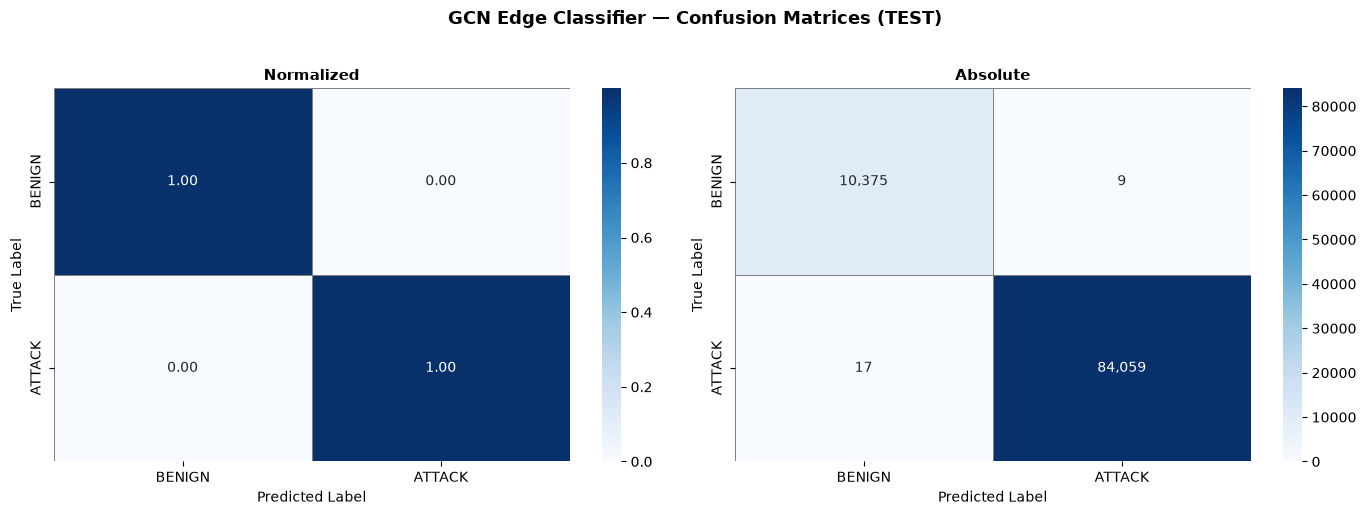

In [9]:
# --- Evaluate GCN on test set ---
test_idx = data.test_mask.nonzero(as_tuple=False).squeeze(1)

test_logits = evaluate_edges(gcn_model, data, test_idx)
test_probs = torch.sigmoid(test_logits).cpu().numpy()
gcn_test_preds = (test_probs >= 0.5).astype(int)
gcn_test_true = data.edge_labels[test_idx].cpu().numpy().astype(int)

gcn_class_names = np.array(['BENIGN', 'ATTACK'])

gcn_acc = accuracy_score(gcn_test_true, gcn_test_preds)
gcn_f1_macro = f1_score(gcn_test_true, gcn_test_preds, average='macro')
gcn_f1_weighted = f1_score(gcn_test_true, gcn_test_preds, average='weighted')

print("=" * 70)
print("Classification Report — GCN Edge Classifier (TEST set)")
print("=" * 70)
print(classification_report(gcn_test_true, gcn_test_preds, target_names=gcn_class_names, digits=4))

# --- Confusion matrices ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('GCN Edge Classifier — Confusion Matrices (TEST)',
             fontsize=13, fontweight='bold', y=1.02)

cm = confusion_matrix(gcn_test_true, gcn_test_preds, labels=[0, 1])
cm_norm = cm.astype('float') / np.maximum(cm.sum(axis=1, keepdims=True), 1)

for idx, (title, cm_data, fmt) in enumerate([
    ('Normalized', cm_norm, '.2f'),
    ('Absolute', cm, ',d'),
]):
    ax = axes[idx]
    sns.heatmap(cm_data, annot=True, fmt=fmt, cmap='Blues',
                xticklabels=gcn_class_names, yticklabels=gcn_class_names,
                ax=ax, vmin=0, linewidths=0.5, linecolor='gray')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_ylabel('True Label')
    ax.set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

---
## Label Propagation for Edge Classification

**Algorithm:** Edge Label Propagation via Shared IP Nodes
1. Initialize: training edges = known labels, val/test edges = 0.5
2. Repeat: node scores = mean of incident edge scores; edge scores = mean of endpoint node scores; clamp training edges
3. Predict: score >= threshold -> ATTACK

**Properties:** 0 parameters, no features used, purely graph-structural.

In [10]:
# --- Edge Label Propagation via Shared IP Nodes ---

# Get data to CPU numpy for LP
lp_labels = data.edge_labels.cpu().numpy().astype(np.float64)
lp_train_mask = data.train_mask.cpu().numpy()
lp_val_mask = data.val_mask.cpu().numpy()
lp_test_mask = data.test_mask.cpu().numpy()

# Initialize edge scores: training = true labels, unlabeled = 0.5
lp_scores = np.full(len(lp_labels), 0.5, dtype=np.float64)
lp_scores[lp_train_mask] = lp_labels[lp_train_mask]

print("=" * 70)
print("Edge Label Propagation via Shared IP Nodes")
print("=" * 70)
print(f"\nEdges: {len(lp_labels):,}  (train={lp_train_mask.sum():,}, "
      f"val={lp_val_mask.sum():,}, test={lp_test_mask.sum():,})")
print(f"Nodes: {num_nodes:,}")
print(f"Max iterations: {lp_cfg.max_iterations},  convergence tol: {lp_cfg.convergence_tol}\n")

t0_lp = time.time()
lp_history_list = []

for lp_it in range(1, lp_cfg.max_iterations + 1):
    # Step 1: Aggregate edge scores -> node scores
    node_sum = np.zeros(num_nodes, dtype=np.float64)
    node_count = np.zeros(num_nodes, dtype=np.float64)
    np.add.at(node_sum, src_idx, lp_scores)
    np.add.at(node_count, src_idx, 1)
    np.add.at(node_sum, dst_idx, lp_scores)
    np.add.at(node_count, dst_idx, 1)
    lp_node_scores = np.where(node_count > 0, node_sum / node_count, 0.5)

    # Step 2: Update unlabeled edge scores from endpoint node means
    new_scores = 0.5 * (lp_node_scores[src_idx] + lp_node_scores[dst_idx])

    # Step 3: Clamp training edges to true labels
    new_scores[lp_train_mask] = lp_labels[lp_train_mask]

    # Convergence check (unlabeled edges only)
    unlabeled = ~lp_train_mask
    lp_delta = np.abs(lp_scores[unlabeled] - new_scores[unlabeled]).max()

    # Validation metrics at default threshold
    val_pred_iter = (new_scores[lp_val_mask] >= 0.5).astype(int)
    val_true_iter = lp_labels[lp_val_mask].astype(int)
    val_f1_iter = f1_score(val_true_iter, val_pred_iter, average='macro')
    val_acc_iter = accuracy_score(val_true_iter, val_pred_iter)

    lp_history_list.append({'iter': lp_it, 'delta': lp_delta,
                            'val_f1': val_f1_iter, 'val_acc': val_acc_iter})

    lp_scores = new_scores

    if lp_it <= 5 or lp_it % 10 == 0:
        print(f"  Iter {lp_it:3d} | delta_max = {lp_delta:.10f} | "
              f"Val Acc = {val_acc_iter:.4f} | Val F1 = {val_f1_iter:.4f}")

    if lp_delta < lp_cfg.convergence_tol:
        print(f"\n  Converged at iteration {lp_it} (delta = {lp_delta:.2e})")
        break

lp_time = time.time() - t0_lp
print(f"\nLabel Propagation completed in {lp_time:.2f}s ({lp_it} iterations)")

Edge Label Propagation via Shared IP Nodes

Edges: 629,540  (train=440,652, val=94,428, test=94,460)
Nodes: 134
Max iterations: 100,  convergence tol: 1e-08

  Iter   1 | delta_max = 0.4668555070 | Val Acc = 0.9238 | Val F1 = 0.8167
  Iter   2 | delta_max = 0.1384637767 | Val Acc = 0.9213 | Val F1 = 0.8088


  Iter   3 | delta_max = 0.0853651865 | Val Acc = 0.9161 | Val F1 = 0.7921
  Iter   4 | delta_max = 0.0662569345 | Val Acc = 0.9159 | Val F1 = 0.7916
  Iter   5 | delta_max = 0.0471421081 | Val Acc = 0.9159 | Val F1 = 0.7913


  Iter  10 | delta_max = 0.0176602547 | Val Acc = 0.9159 | Val F1 = 0.7916


  Iter  20 | delta_max = 0.0091951865 | Val Acc = 0.9252 | Val F1 = 0.8208


  Iter  30 | delta_max = 0.0058071269 | Val Acc = 0.9360 | Val F1 = 0.8525


...

  Iter  60 | delta_max = 0.0014604830 | Val Acc = 0.9369 | Val F1 = 0.8549


  Iter  70 | delta_max = 0.0009218268 | Val Acc = 0.9369 | Val F1 = 0.8549


  Iter  80 | delta_max = 0.0005818364 | Val Acc = 0.9369 | Val F1 = 0.8550


  Iter  90 | delta_max = 0.0003672418 | Val Acc = 0.9369 | Val F1 = 0.8550


  Iter 100 | delta_max = 0.0002317945 | Val Acc = 0.9369 | Val F1 = 0.8550

Label Propagation completed in 9.32s (100 iterations)


In [11]:
# --- Tune threshold on validation set ---
print(f"{'Threshold Tuning on Validation Set':=^70}")
val_scores_lp = lp_scores[lp_val_mask]
val_true_lp = lp_labels[lp_val_mask].astype(int)

lp_best_thr = 0.5
lp_best_val_f1 = 0.0
lp_thr_results = []

for thr in np.arange(0.01, 1.0, lp_cfg.threshold_search_step):
    preds = (val_scores_lp >= thr).astype(int)
    f1_m = f1_score(val_true_lp, preds, average='macro')
    lp_thr_results.append((thr, f1_m))
    if f1_m > lp_best_val_f1:
        lp_best_val_f1 = f1_m
        lp_best_thr = thr

print(f"  Best threshold: {lp_best_thr:.2f} (Val Macro F1: {lp_best_val_f1:.4f})")

print(f"\n  Threshold sweep (selected):")
for thr, f1_m in lp_thr_results:
    if abs(thr - lp_best_thr) < 0.001 or any(abs(thr - t) < 0.001 for t in (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)):
        marker = " <-- best" if abs(thr - lp_best_thr) < 0.001 else ""
        print(f"    thr={thr:.2f}  Macro F1={f1_m:.4f}{marker}")

# --- Generate test predictions ---
lp_test_scores = lp_scores[lp_test_mask]
lp_test_preds = (lp_test_scores >= lp_best_thr).astype(int)
lp_test_true = lp_labels[lp_test_mask].astype(int)

==================Threshold Tuning on Validation Set==================


  Best threshold: 0.54 (Val Macro F1: 0.8973)

  Threshold sweep (selected):
    thr=0.10  Macro F1=0.7430
    thr=0.20  Macro F1=0.7430
    thr=0.30  Macro F1=0.7430
    thr=0.40  Macro F1=0.7628
    thr=0.50  Macro F1=0.8550
    thr=0.54  Macro F1=0.8973 <-- best
    thr=0.60  Macro F1=0.8973
    thr=0.70  Macro F1=0.8973
    thr=0.80  Macro F1=0.8973
    thr=0.90  Macro F1=0.7391


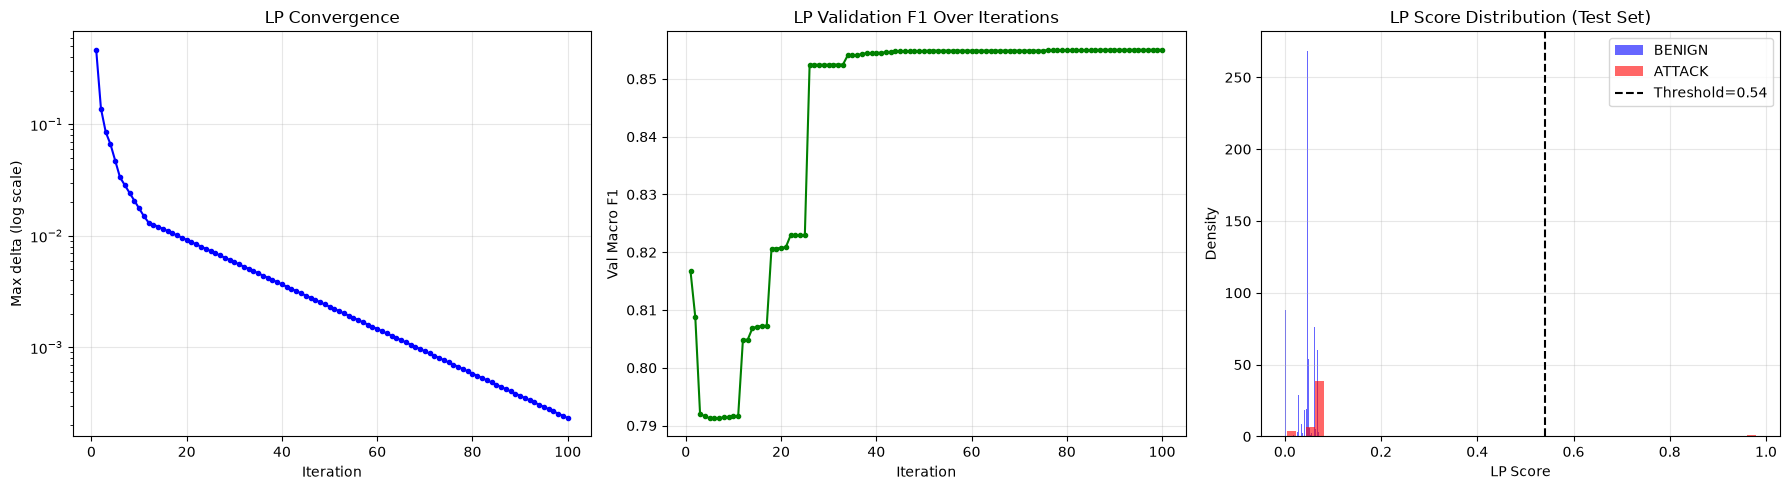


Test predictions ready: 94,460 flows, threshold=0.54


In [12]:
# --- LP Convergence & Score Distribution Plots ---
lp_hist_df = pd.DataFrame(lp_history_list)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Convergence — delta
axes[0].semilogy(lp_hist_df['iter'], lp_hist_df['delta'], 'b-o', markersize=3)
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Max delta (log scale)')
axes[0].set_title('LP Convergence')
axes[0].grid(True, alpha=0.3)

# Convergence — val F1
axes[1].plot(lp_hist_df['iter'], lp_hist_df['val_f1'], 'g-o', markersize=3)
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Val Macro F1')
axes[1].set_title('LP Validation F1 Over Iterations')
axes[1].grid(True, alpha=0.3)

# Score distribution for test set
test_benign_scores = lp_test_scores[lp_test_true == 0]
test_attack_scores = lp_test_scores[lp_test_true == 1]
axes[2].hist(test_benign_scores, bins=50, alpha=0.6, label='BENIGN', color='blue', density=True)
axes[2].hist(test_attack_scores, bins=50, alpha=0.6, label='ATTACK', color='red', density=True)
axes[2].axvline(lp_best_thr, color='black', linestyle='--', label=f'Threshold={lp_best_thr:.2f}')
axes[2].set_xlabel('LP Score')
axes[2].set_ylabel('Density')
axes[2].set_title('LP Score Distribution (Test Set)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nTest predictions ready: {len(lp_test_preds):,} flows, threshold={lp_best_thr:.2f}")

Classification Report — Label Propagation (TEST set)
              precision    recall  f1-score   support

      BENIGN     0.1128    1.0000    0.2028     10384
      ATTACK     1.0000    0.0289    0.0562     84076

    accuracy                         0.1357     94460
   macro avg     0.5564    0.5145    0.1295     94460
weighted avg     0.9025    0.1357    0.0724     94460



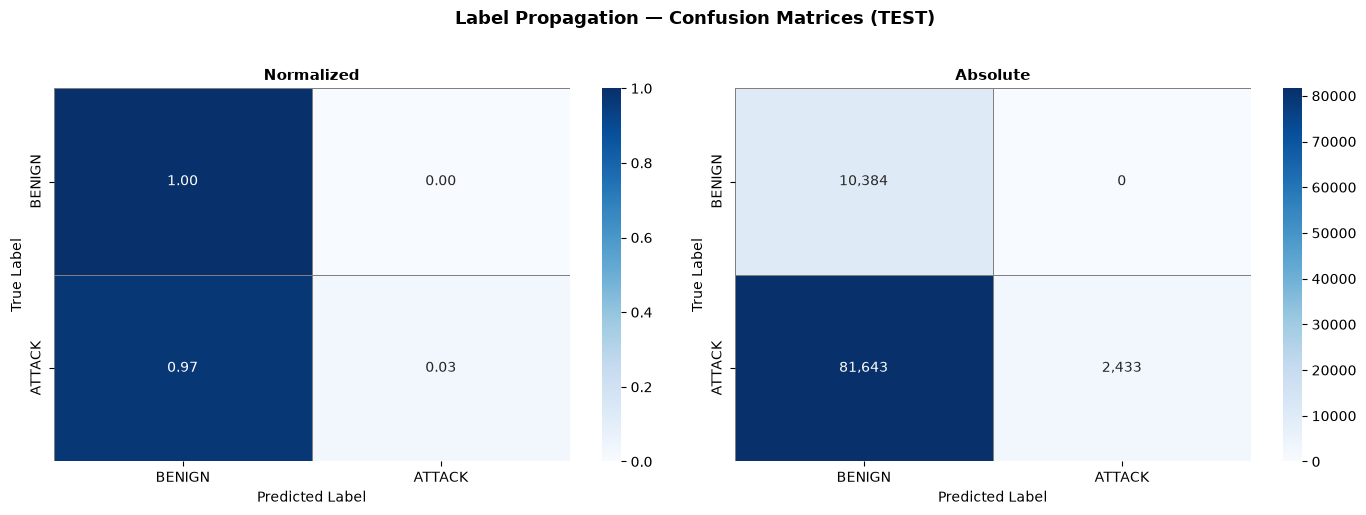

In [13]:
# --- LP Classification Report & Confusion Matrices ---

lp_acc = accuracy_score(lp_test_true, lp_test_preds)
lp_f1_macro = f1_score(lp_test_true, lp_test_preds, average='macro')
lp_f1_weighted = f1_score(lp_test_true, lp_test_preds, average='weighted')

lp_class_names = np.array(['BENIGN', 'ATTACK'])

print("=" * 70)
print("Classification Report — Label Propagation (TEST set)")
print("=" * 70)
print(classification_report(lp_test_true, lp_test_preds, target_names=lp_class_names, digits=4))

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Label Propagation — Confusion Matrices (TEST)',
             fontsize=13, fontweight='bold', y=1.02)

cm_lp = confusion_matrix(lp_test_true, lp_test_preds, labels=[0, 1])
cm_lp_norm = cm_lp.astype('float') / np.maximum(cm_lp.sum(axis=1, keepdims=True), 1)

for idx, (title, cm_d, fmt) in enumerate([
    ('Normalized', cm_lp_norm, '.2f'),
    ('Absolute', cm_lp, ',d'),
]):
    ax = axes[idx]
    sns.heatmap(cm_d, annot=True, fmt=fmt, cmap='Blues',
                xticklabels=lp_class_names, yticklabels=lp_class_names,
                ax=ax, vmin=0, linewidths=0.5, linecolor='gray')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_ylabel('True Label')
    ax.set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

---
## Three-Way Comparison & Ensemble

In [14]:
# --- Load XGBoost baseline results from 02_standard_ml (if available) ---
xgb_results_path = prepared_data_dir / 'xgb_baseline_results.npz'
xgb_aligned = False

comparison_rows_3 = []

if xgb_results_path.exists():
    xgb_baseline = np.load(xgb_results_path)
    xgb_test_preds = xgb_baseline['test_preds']
    xgb_acc = float(xgb_baseline['accuracy'])
    xgb_f1_macro = float(xgb_baseline['f1_macro'])
    xgb_f1_weighted = float(xgb_baseline['f1_weighted'])
    xgb_time = float(xgb_baseline['train_time'])
    print(f"Loaded XGBoost baseline results from {xgb_results_path}")

    # The test sets must be the same flows in the same order (same prepared data, same split)
    xgb_aligned = (len(xgb_test_preds) == len(lp_test_true)
                   and ('test_true' not in xgb_baseline or np.array_equal(xgb_baseline['test_true'], lp_test_true)))
    if xgb_aligned:
        comparison_rows_3.append({
            'Model': 'XGBoost (Per-Label Chrono)',
            'Accuracy': f"{xgb_acc:.4f}",
            'Macro F1': f"{xgb_f1_macro:.4f}",
            'Weighted F1': f"{xgb_f1_weighted:.4f}",
            'Train Time': f"{xgb_time:.1f}s"
        })
    else:
        print(f"WARNING: XGBoost test set ({len(xgb_test_preds):,} flows) differs from the graph test set "
              f"({len(lp_test_true):,}). Re-run 02_standard_ml.ipynb on the current prepared data. Skipping XGBoost.")
else:
    print(f"XGBoost baseline file not found: {xgb_results_path}")
    print("Run 02_standard_ml.ipynb first if you want three-way comparison.")

# --- Comparison Table ---
print("\n" + "=" * 70)
print("Model Comparison — Test Set")
print("=" * 70)

comparison_rows_3.extend([
    {
        'Model': 'GCN Edge Classifier',
        'Accuracy': f"{gcn_acc:.4f}",
        'Macro F1': f"{gcn_f1_macro:.4f}",
        'Weighted F1': f"{gcn_f1_weighted:.4f}",
        'Train Time': f"{gcn_total_time:.1f}s"
    },
    {
        'Model': 'Label Propagation',
        'Accuracy': f"{lp_acc:.4f}",
        'Macro F1': f"{lp_f1_macro:.4f}",
        'Weighted F1': f"{lp_f1_weighted:.4f}",
        'Train Time': f"{lp_time:.1f}s"
    },
])

comparison_df_3 = pd.DataFrame(comparison_rows_3)
print(comparison_df_3.to_string(index=False))

Loaded XGBoost baseline results from prepared_data/xgb_baseline_results.npz

Model Comparison — Test Set
                     Model Accuracy Macro F1 Weighted F1 Train Time
XGBoost (Per-Label Chrono)   0.9997   0.9993      0.9997       1.3s
       GCN Edge Classifier   0.9997   0.9993      0.9997     150.0s
         Label Propagation   0.1357   0.1295      0.0724       9.3s


In [15]:
# --- Three-Way Error Analysis: XGBoost vs GCN vs LP ---

if ens_cfg.run_ensemble and xgb_aligned:
    n_total_3 = len(lp_test_true)
    xgb_err = (xgb_test_preds != lp_test_true)
    gcn_err = (gcn_test_preds != lp_test_true)
    lp_err  = (lp_test_preds  != lp_test_true)

    print(f"{'Three-Way Error Analysis: XGBoost vs GCN vs LP':=^70}")
    print(f"\nTotal test flows: {n_total_3:,}")
    print(f"  XGBoost errors:  {xgb_err.sum():>6,}  ({xgb_err.sum()/n_total_3*100:.3f}%)")
    print(f"  GCN errors:      {gcn_err.sum():>6,}  ({gcn_err.sum()/n_total_3*100:.3f}%)")
    print(f"  LP errors:       {lp_err.sum():>6,}  ({lp_err.sum()/n_total_3*100:.3f}%)")

    # Venn-style breakdown
    all_correct   = int((~xgb_err & ~gcn_err & ~lp_err).sum())
    all_wrong     = int((xgb_err  &  gcn_err &  lp_err).sum())
    only_xgb_err3 = int((xgb_err  & ~gcn_err & ~lp_err).sum())
    only_gcn_err3 = int((~xgb_err &  gcn_err & ~lp_err).sum())
    only_lp_err3  = int((~xgb_err & ~gcn_err &  lp_err).sum())
    xgb_gcn_err   = int((xgb_err  &  gcn_err & ~lp_err).sum())
    xgb_lp_err    = int((xgb_err  & ~gcn_err &  lp_err).sum())
    gcn_lp_err    = int((~xgb_err &  gcn_err &  lp_err).sum())

    print(f"\n{'Agreement Breakdown':=^70}")
    print(f"  All 3 correct:         {all_correct:>8,}  ({all_correct/n_total_3*100:.2f}%)")
    print(f"  All 3 wrong:           {all_wrong:>8,}  ({all_wrong/n_total_3*100:.3f}%)")
    print(f"  Only XGBoost wrong:    {only_xgb_err3:>8,}  ({only_xgb_err3/n_total_3*100:.3f}%)")
    print(f"  Only GCN wrong:        {only_gcn_err3:>8,}  ({only_gcn_err3/n_total_3*100:.3f}%)")
    print(f"  Only LP wrong:         {only_lp_err3:>8,}  ({only_lp_err3/n_total_3*100:.3f}%)")
    print(f"  XGBoost + GCN wrong:   {xgb_gcn_err:>8,}  ({xgb_gcn_err/n_total_3*100:.3f}%)")
    print(f"  XGBoost + LP wrong:    {xgb_lp_err:>8,}  ({xgb_lp_err/n_total_3*100:.3f}%)")
    print(f"  GCN + LP wrong:        {gcn_lp_err:>8,}  ({gcn_lp_err/n_total_3*100:.3f}%)")

    # Rescue analysis
    print(f"\n{'Rescue Analysis':=^70}")
    for name_a, err_a, others in [
        ('XGBoost', xgb_err, [('GCN', gcn_err), ('LP', lp_err)]),
        ('GCN',     gcn_err, [('XGBoost', xgb_err), ('LP', lp_err)]),
        ('LP',      lp_err,  [('XGBoost', xgb_err), ('GCN', gcn_err)]),
    ]:
        if err_a.sum() == 0:
            continue
        print(f"  {name_a} ({err_a.sum():,} errors):")
        for name_b, err_b in others:
            rescues = int((err_a & ~err_b).sum())
            print(f"    {name_b} rescues: {rescues:,} ({rescues/err_a.sum()*100:.1f}%)")

    # --- Majority-vote ensemble (2 of 3) ---
    print(f"\n{'Ensemble: Majority Vote (2 of 3 say ATTACK)':=^70}")
    vote_sum = xgb_test_preds.astype(int) + gcn_test_preds.astype(int) + lp_test_preds.astype(int)
    majority_preds = (vote_sum >= 2).astype(int)
    maj_acc = accuracy_score(lp_test_true, majority_preds)
    maj_f1_macro = f1_score(lp_test_true, majority_preds, average='macro')
    maj_f1_weighted = f1_score(lp_test_true, majority_preds, average='weighted')

    print(f"  Accuracy:    {maj_acc:.4f}")
    print(f"  Macro F1:    {maj_f1_macro:.4f}")
    print(f"  Weighted F1: {maj_f1_weighted:.4f}")

    # Per-class error breakdown
    print(f"\n{'Error Breakdown by True Class':=^70}")
    for cls_v, cls_n in [(0, 'BENIGN'), (1, 'ATTACK')]:
        cls_m = (lp_test_true == cls_v)
        n_c = cls_m.sum()
        print(f"  {cls_n} ({n_c:,} flows):")
        for name, err in [('XGBoost', xgb_err), ('GCN', gcn_err), ('LP', lp_err),
                          ('Majority', majority_preds != lp_test_true)]:
            n_e = int((err & cls_m).sum())
            print(f"    {name:12s} errors: {n_e:>6,}  ({n_e/n_c*100:.2f}%)")
else:
    print("Ensemble analysis skipped (disabled, or no aligned XGBoost baseline).")

print(f"\nNotebook runtime: {(time.time() - NOTEBOOK_T0) / 60:.1f} min")

============Three-Way Error Analysis: XGBoost vs GCN vs LP============

Total test flows: 94,460
  XGBoost errors:      26  (0.028%)
  GCN errors:          26  (0.028%)
  LP errors:       81,643  (86.431%)

=========================Agreement Breakdown==========================
  All 3 correct:           12,788  (13.54%)
  All 3 wrong:                  5  (0.005%)
  Only XGBoost wrong:          13  (0.014%)
  Only GCN wrong:              13  (0.014%)
  Only LP wrong:           81,628  (86.415%)
  XGBoost + GCN wrong:          3  (0.003%)
  XGBoost + LP wrong:           5  (0.005%)
  GCN + LP wrong:               5  (0.005%)

===========================Rescue Analysis============================
  XGBoost (26 errors):
    GCN rescues: 18 (69.2%)
    LP rescues: 16 (61.5%)
  GCN (26 errors):
    XGBoost rescues: 18 (69.2%)
    LP rescues: 16 (61.5%)
  LP (81,643 errors):
    XGBoost rescues: 81,633 (100.0%)
    GCN rescues: 81,633 (100.0%)

=============Ensemble: Majority Vote (2 of 3 say